# DL · 03 Final Model — test, explain, refit on all data, save and reload
Run after `02_mlp_training.ipynb`, or set `RETRAIN = False` to use the trained networks already saved in `DL/Models/`.

* **Evaluation model** — the selected network trained on all 1940–2018 rows; scored once on the untouched 2021–2023 test years.
* **Final model** — the same design refitted on **all 2.8 million rows (1940–2023)** for deployment. It has no honest test score of its own; its expected accuracy is the evaluation model's.

**Project team**

| Team member | Enrollment number |
|---|---|
| Dhruv Kumar | 2401010152 |
| Ritesh | 2041010383 |
| Yash Kumar | 2401010512 |
| Parul | 2401010321 |
| Punit | 2401010359 |

## 1. Imports, network definition and evaluation functions

In [1]:
from pathlib import Path
import json, hashlib, zipfile
import numpy as np
import pandas as pd
from IPython.display import display, Image
import copy, random, platform, time
from datetime import UTC, datetime
from importlib.metadata import version
import joblib
import torch
from torch import nn
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
# Locate the repository root from either the repo root or the notebook folder.
_here = Path.cwd().resolve()
ROOT = next((p for p in [_here, *_here.parents] if (p / "Datasets" / "Water_Quality_Dataset.zip").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the Water_Quality_Prediction repository.")
PART = ROOT / "DL"              # This part of the project
DATA = ROOT / "Datasets"            # Shared source data
CACHE = DATA / "_working"           # Shared extracted CSV; ignored by Git
WORK = PART / "_working"            # Intermediate files for this part; ignored by Git
FIGURES = PART / "figures"
MODELS = PART / "Models"
RESULTS = PART / "Results"
for folder in [CACHE, WORK, FIGURES, MODELS, RESULTS]:
    folder.mkdir(exist_ok=True)
CSV = CACHE / "Combined_dataset.csv"
EXPECTED_SHA256 = "81ced159f465aa5ab004b77130e5f7147c698876ddbf2f97807e31c9d0e8d714"
FEATURES = [
    "Ammonia (mg/l)",
    "Biochemical Oxygen Demand (mg/l)",
    "Dissolved Oxygen (mg/l)",
    "Orthophosphate (mg/l)",
    "pH (ph units)",
    "Temperature (cel)",
    "Nitrogen (mg/l)",
    "Nitrate (mg/l)",
]
SHORT_NAMES = ["Ammonia", "BOD", "Dissolved oxygen", "Orthophosphate", "pH", "Temperature", "Nitrogen", "Nitrate"]
TARGET = "CCME_Values"
OBJECTIVES = np.array([0.5, 6, 14, 0.05, 8.5, 25, 20, 45])
META = ["Country", "Area", "Waterbody Type", "Date"]
BANDS = ["Poor", "Marginal", "Fair", "Good", "Excellent"]


def sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def ensure_csv():
    """Extract the unmodified Figshare CSV from the shared ZIP once, then verify it."""
    if not CSV.exists():
        archive = DATA / "Water_Quality_Dataset.zip"
        if archive.exists():
            import shutil
            with zipfile.ZipFile(archive) as z, z.open("Combined_dataset.csv") as src, CSV.open("wb") as dst:
                shutil.copyfileobj(src, dst)
        else:
            import urllib.request
            urllib.request.urlretrieve("https://ndownloader.figshare.com/files/50757321", CSV)
    assert sha256(CSV) == EXPECTED_SHA256, "Dataset checksum differs from the documented release."
    return CSV


def source_formula(frame):
    """Reconstruct released labels, including denominator 12 and upper-only tests.

    Diagnostic only: this intentionally preserves source methodological issues.
    It is NOT an implementation of the official site/time-window CCME standard.
    """
    x = frame[FEATURES].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=float)
    failed = (x > OBJECTIVES).sum(axis=1)
    excursion = np.maximum(x / OBJECTIVES - 1, 0).sum(axis=1)
    f1 = 100 * failed / 12
    nse = excursion / 12
    f3 = nse / (0.01 * nse + 0.01)
    result = 100 - np.sqrt(2 * f1**2 + f3**2) / 1.732
    result[~np.isfinite(x).all(axis=1)] = np.nan
    return result


def quality_features(frame):
    """Mask invalid readings without deleting pollution extremes or guessing units.

    pH outside [0,14] and negative concentrations become missing. Temperature
    outside [-5,50] C is flagged for review, not converted. Every input gets a
    fixed missing/invalid flag, so the model always receives 16 columns.
    """
    absent = set(FEATURES) - set(frame.columns)
    if absent:
        raise ValueError(f"Missing required measurement columns: {sorted(absent)}")
    x = frame[FEATURES].apply(pd.to_numeric, errors="coerce").astype(float)
    x = x.replace([np.inf, -np.inf], np.nan)
    for col in FEATURES:
        if col == "pH (ph units)":
            invalid = ~x[col].between(0, 14)
        elif col == "Temperature (cel)":
            invalid = ~x[col].between(-5, 50)
        else:
            invalid = x[col] < 0
        x.loc[invalid, col] = np.nan
    flags = x.isna().astype(float)
    flags.columns = [f"{col}__missing" for col in FEATURES]
    return pd.concat([x, flags], axis=1)


def dump_json(path, payload):
    Path(path).write_text(json.dumps(payload, indent=2, allow_nan=False) + "\n")

def seed_everything(seed, threads=4):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(threads)
    torch.use_deterministic_algorithms(True)

class MLP(nn.Module):
    """Feedforward network: [Linear -> ReLU (-> Dropout)] x hidden layers -> Linear(1)."""
    def __init__(self, input_dim=16, widths=(128, 64), dropout=0.0):
        super().__init__()
        layers, size = [], input_dim
        for width in widths:
            layers += [nn.Linear(size, width), nn.ReLU()]
            if dropout:
                layers.append(nn.Dropout(dropout))
            size = width
        layers.append(nn.Linear(size, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x).squeeze(-1)

def predict_mlp(model, x, batch_size=65536):
    """Predict in index points (0-100); the network itself works on target/100."""
    model.eval()
    out = []
    with torch.inference_mode():
        for start in range(0, len(x), batch_size):
            batch = torch.as_tensor(np.asarray(x[start:start + batch_size]), dtype=torch.float32)
            out.append(model(batch).numpy() * 100)
    return np.clip(np.concatenate(out), 0, 100)

def fit_mlp(x, y, xv, yv, spec, config, verbose_every=10):
    """Train one network with AdamW + MSE on target/100.

    spec["schedule"] = "constant" keeps the learning rate fixed (the original setup);
    "onecycle" warms up to spec["lr"] and anneals it to ~0, which lets the network
    settle into a sharper minimum. With validation data the best-RMSE epoch is kept;
    without it (final refit on all years) the last epoch is kept.
    """
    seed_everything(config["seed"], config["threads"])
    model = MLP(x.shape[1], spec["widths"], spec["dropout"])
    optimizer = torch.optim.AdamW(model.parameters(), lr=spec["lr"], weight_decay=config["weight_decay"])
    tx = torch.as_tensor(np.asarray(x), dtype=torch.float32)
    ty = torch.as_tensor(np.asarray(y) / 100, dtype=torch.float32)
    steps_per_epoch = (len(tx) + config["batch_size"] - 1) // config["batch_size"]
    scheduler = None
    if spec["schedule"] == "onecycle":
        scheduler = torch.optim.lr_scheduler.OneCycleLR(
            optimizer, max_lr=spec["lr"], total_steps=spec["epochs"] * steps_per_epoch, pct_start=0.1)
    best_score, best_state, history = float("inf"), None, []
    tick = time.perf_counter()
    for epoch in range(spec["epochs"]):
        model.train()
        total = 0.0
        for ids in torch.randperm(len(tx)).split(config["batch_size"]):
            optimizer.zero_grad(set_to_none=True)
            loss = nn.functional.mse_loss(model(tx[ids]), ty[ids])
            loss.backward()
            optimizer.step()
            if scheduler is not None:
                scheduler.step()
            total += loss.item() * len(ids)
        row = {"epoch": epoch + 1, "train_rmse": float(np.sqrt(total / len(tx)) * 100),
               "lr": optimizer.param_groups[0]["lr"]}
        if xv is not None:
            row["validation_rmse"] = float(np.sqrt(np.mean((predict_mlp(model, xv) - np.asarray(yv)) ** 2)))
            if row["validation_rmse"] < best_score:
                best_score, best_state = row["validation_rmse"], copy.deepcopy(model.state_dict())
        history.append(row)
        if epoch == 0 or (epoch + 1) % verbose_every == 0:
            shown = f"validation RMSE {row['validation_rmse']:.4f}" if xv is not None else f"train RMSE {row['train_rmse']:.4f}"
            print(f"  {spec['name']}: epoch {epoch + 1:>3}, {shown}, {time.perf_counter() - tick:.0f}s", flush=True)
    if best_state is not None:
        model.load_state_dict(best_state)
    model.eval()
    return model, history

def metrics(y, prediction):
    return {
        "mae": float(mean_absolute_error(y, prediction)),
        "rmse": float(np.sqrt(mean_squared_error(y, prediction))),
        "r2": float(r2_score(y, prediction)),
    }

def residual_quantile(y, prediction, alpha=0.1):
    """Finite-sample-corrected quantile of held-out absolute residuals."""
    residual = np.abs(np.asarray(y) - np.asarray(prediction))
    rank = int(np.ceil((len(residual) + 1) * (1 - alpha)))
    if rank > len(residual):
        return float("inf")
    return float(np.partition(residual, rank - 1)[rank - 1])

def intervals(prediction, radius):
    return np.clip(prediction - radius, 0, 100), np.clip(prediction + radius, 0, 100)

def interval_metrics(y, prediction, radius):
    lower, upper = intervals(prediction, radius)
    return {
        "coverage": float(np.mean((y >= lower) & (y <= upper))),
        "mean_width": float(np.mean(upper - lower)),
        "radius": radius,
    }

def read_dataset(path):
    df = pd.read_csv(path)
    required = set(META + FEATURES + [TARGET, "CCME_WQI"])
    if required - set(df.columns):
        raise ValueError(f"Dataset lacks columns: {sorted(required - set(df.columns))}")
    return df

def prepare(frame):
    """Keep source row IDs for traceability; never impute a target or a date."""
    df = frame.copy()
    df.insert(0, "source_row", np.arange(len(df)))
    duplicates = df.drop(columns="source_row").duplicated()
    date = pd.to_datetime(df.Date, format="%d-%m-%Y", errors="coerce")
    y = pd.to_numeric(df[TARGET], errors="coerce")
    invalid = date.isna() | ~y.between(0, 100) | df.Country.isna() | df.Area.isna()
    counts = {
        "exact_duplicates_removed": int(duplicates.sum()),
        "invalid_metadata_or_target": int(invalid.sum()),
    }
    df = df.loc[~duplicates & ~invalid].copy()
    df["parsed_date"] = date.loc[df.index]
    df[TARGET] = y.loc[df.index]
    return df, counts

def temporal_split(df, config):
    bounds = [pd.Timestamp(config[k]) for k in ["train_end", "validation_end", "calibration_end"]]
    if not bounds[0] < bounds[1] < bounds[2]:
        raise ValueError("Split boundaries must increase strictly")
    date = df.parsed_date
    masks = [
        date <= bounds[0],
        (date > bounds[0]) & (date <= bounds[1]),
        (date > bounds[1]) & (date <= bounds[2]),
        date > bounds[2],
    ]
    splits = dict(zip(["train", "validation", "calibration", "test"], [df.loc[m].copy() for m in masks]))
    if any(part.empty for part in splits.values()):
        raise ValueError("Every chronological partition must contain observations")
    return splits

def sample(frame, cap, seed):
    if cap and len(frame) > cap:
        return frame.sample(n=cap, random_state=seed).sort_index()
    return frame

def split_summary(part):
    return {
        "rows": len(part),
        "start": str(part.parsed_date.min().date()),
        "end": str(part.parsed_date.max().date()),
        "countries": part.Country.value_counts().to_dict(),
        "sites": int(part.groupby(["Country", "Area"]).ngroups),
        "mean_target": float(part[TARGET].mean()),
    }

In [2]:
# True: evaluate the network selected in 02 and refit it on all years (several minutes).
# False: load the saved networks from DL/Models and inspect the saved results.
RETRAIN = True
TRAIN = {"seed": 42, "threads": 4, "batch_size": 2048, "weight_decay": 1e-4}
if RETRAIN:
    bundle = joblib.load(WORK / "prepared.joblib")
    config, manifest, neural_pre = bundle["config"], bundle["manifest"], bundle["neural_pre"]
    xc, yc, xt, yt = bundle["xc"], bundle["yc"], bundle["xt"], bundle["yt"]
    test_meta = bundle["test_meta"]
    spec = json.loads((WORK / "selected_spec.json").read_text())
    reference_spec = json.loads((WORK / "reference_spec.json").read_text())
    mlp = MLP(16, spec["widths"], spec["dropout"])
    mlp.load_state_dict(torch.load(WORK / "selected_mlp.pt", weights_only=True))
    reference = MLP(16, reference_spec["widths"], reference_spec["dropout"])
    reference.load_state_dict(torch.load(WORK / "reference_mlp.pt", weights_only=True))
    start = time.perf_counter()
    print("Selected network:", spec["name"])
else:
    assert (MODELS / "mlp_final_all_years.pt").exists(), "No saved networks found in DL/Models/."
    print("Using the saved networks and measured results.")

Selected network: B · 128-64 · no dropout


## 2. Untouched test evaluation (2021–2023) and 90% intervals
Both the original small-sample network and the new full-data network are scored on all 202,886 test rows. The 2020 calibration year sets a constant 90% residual interval radius. For context, the XGBoost result from the AML part is added when `AML/Results/metrics.csv` exists.

In [3]:
if RETRAIN:
    models = {"MLP · 300k sample (original)": reference, "MLP · full data": mlp}
    rows, subgroups, radii = [], [], {}
    predictions = test_meta.copy()
    for name, model in models.items():
        prediction = predict_mlp(model, xt)
        radius = residual_quantile(yc, predict_mlp(model, xc), config["alpha"])
        radii[name] = radius
        rows.append({"model": name, **metrics(yt, prediction), **interval_metrics(yt, prediction, radius)})
        predictions[name] = prediction
        for group_type, column, groups_ in [("country", "Country", sorted(test_meta.Country.unique())),
                                            ("source_index_band", "CCME_WQI", BANDS)]:
            for group in groups_:
                ids = (test_meta[column] == group).to_numpy()
                if ids.sum() >= 2:
                    subgroups.append({"model": name, "group_type": group_type, "group": group,
                                      "rows": int(ids.sum()), **metrics(yt[ids], prediction[ids]),
                                      **interval_metrics(yt[ids], prediction[ids], radius)})
    low, high = intervals(predictions["MLP · full data"].to_numpy(), radii["MLP · full data"])
    predictions["lower_90"], predictions["upper_90"] = low, high
    predictions.to_csv(RESULTS / "predictions_test.csv.gz", index=False, compression="gzip")
    pd.DataFrame(rows).to_csv(RESULTS / "metrics.csv", index=False)
    pd.DataFrame(subgroups).to_csv(RESULTS / "subgroup_metrics.csv", index=False)

scores = pd.read_csv(RESULTS / "metrics.csv")
aml_metrics = ROOT / "AML" / "Results" / "metrics.csv"
comparison = scores.copy()
if aml_metrics.exists():
    xgb = pd.read_csv(aml_metrics).query("model == 'XGBoost'").assign(model="XGBoost (AML part, reference)")
    comparison = pd.concat([comparison, xgb[comparison.columns.intersection(xgb.columns)]], ignore_index=True)
display(comparison[["model", "mae", "rmse", "r2", "coverage", "mean_width"]].round(4))

,model,mae,rmse,r2,coverage,mean_width
0,MLP · 300k sample (original),0.4649,0.9223,0.9934,0.9059,2.3693
1,MLP · full data,0.0279,0.1357,0.9999,0.8969,0.0791
2,"XGBoost (AML part, reference)",0.1099,0.4262,0.9986,0.8840,0.3073


## 3. Which measurements does the network rely on?
Permutation importance on 2,000 validation rows: shuffle one measurement together with its quality flag, three repeats, and record the rise in MAE. This explains how the network emulates the formula — not environmental causality.

In [4]:
if RETRAIN:
    explain_frame = bundle["explain_frame"]
    explain_x, explain_y = quality_features(explain_frame), explain_frame[TARGET].to_numpy()
    predict_frame = lambda frame: predict_mlp(mlp, neural_pre.transform(frame).astype("float32"))
    baseline_mae = metrics(explain_y, predict_frame(explain_x))["mae"]
    rng = np.random.default_rng(config["seed"])
    rows = []
    for col, short in zip(FEATURES, SHORT_NAMES):
        deltas = []
        for _ in range(3):
            shuffled = explain_x.copy()
            ids = rng.permutation(len(explain_x))
            shuffled.loc[:, [col, f"{col}__missing"]] = explain_x.iloc[ids][[col, f"{col}__missing"]].to_numpy()
            deltas.append(metrics(explain_y, predict_frame(shuffled))["mae"] - baseline_mae)
        rows.append({"feature": short, "mae_increase": float(np.mean(deltas)), "repeat_std": float(np.std(deltas))})
    pd.DataFrame(rows).to_csv(RESULTS / "permutation_importance.csv", index=False)
display(pd.read_csv(RESULTS / "permutation_importance.csv").sort_values("mae_increase", ascending=False).round(4))

,feature,mae_increase,repeat_std
3,Orthophosphate,8.5497,0.1578
0,Ammonia,2.6764,0.0849
1,BOD,1.0311,0.0184
4,pH,0.2576,0.0014
6,Nitrogen,0.1372,0.0014
2,Dissolved oxygen,0.0353,0.0019
5,Temperature,0.0333,0.0019
7,Nitrate,0.0037,0.0003


## 4. Final model: refit on the whole dataset (1940–2023)
Same architecture, optimizer, schedule and number of epochs as the selected network, but trained on every cleaned row. The input pipeline is refitted on all rows too. There is no held-out data left, so the last epoch is kept (with a one-cycle schedule the last epochs are also the best ones on validation).

In [5]:
if RETRAIN:
    print("Reading the whole cleaned dataset for the final refit...", flush=True)
    clean, _ = prepare(read_dataset(ensure_csv()))
    final_pre = make_pipeline(
        SimpleImputer(strategy="median", keep_empty_features=True),
        FunctionTransformer(np.arcsinh, validate=False),
        StandardScaler(),
    )
    x_all = final_pre.fit_transform(quality_features(clean)).astype("float32")
    y_all = clean[TARGET].to_numpy("float32")
    del clean
    print(f"Refitting {spec['name']} on {len(x_all):,} rows...", flush=True)
    final_model, final_history = fit_mlp(x_all, y_all, None, None, {**spec, "name": "Final · all years"}, TRAIN)
    final_fit = metrics(y_all, predict_mlp(final_model, x_all))
    print(f"Final model fit on all rows (not a test score): RMSE {final_fit['rmse']:.4f}")
    del x_all, y_all

Reading the whole cleaned dataset for the final refit...


Refitting B · 128-64 · no dropout on 2,818,006 rows...


  Final · all years: epoch   1, train RMSE 24.6705, 1s


  Final · all years: epoch  10, train RMSE 1.1735, 8s


  Final · all years: epoch  20, train RMSE 2.0694, 16s


  Final · all years: epoch  30, train RMSE 0.5311, 24s


  Final · all years: epoch  40, train RMSE 0.3434, 32s


  Final · all years: epoch  50, train RMSE 0.2477, 40s


  Final · all years: epoch  60, train RMSE 0.2185, 48s


Final model fit on all rows (not a test score): RMSE 0.2183


## 5. Save the networks and reproducibility information

In [6]:
if RETRAIN:
    torch.save(mlp.state_dict(), MODELS / "mlp_evaluation.pt")
    torch.save(final_model.state_dict(), MODELS / "mlp_final_all_years.pt")
    joblib.dump({"evaluation": neural_pre, "final": final_pre}, MODELS / "preprocessing.joblib")
    metadata = {
        "schema_version": 2,
        "features": FEATURES,
        "architecture": {"input_dim": 16, "widths": spec["widths"], "dropout": spec["dropout"], "activation": "ReLU"},
        "training": {**TRAIN, "optimizer": "AdamW", "loss": "MSE on target/100", "schedule": spec["schedule"],
                     "max_lr": spec["lr"], "epochs": spec["epochs"]},
        "models": {
            "mlp_evaluation.pt": {"trained_on": "all 1940-2018 rows", "rows": int(manifest["train"]["rows"]),
                                  "preprocessor": "evaluation"},
            "mlp_final_all_years.pt": {"trained_on": "all 1940-2023 rows", "rows": int(manifest["retained_rows"]),
                                       "preprocessor": "final"},
        },
        "interval_radius_90": radii["MLP · full data"],
        "alpha": config["alpha"],
        "target": TARGET,
        "task": "Emulation of the source-defined, row-level derived index",
        "warning": "This index is not official site-period CCME WQI or drinking-water safety.",
    }
    dump_json(MODELS / "metadata.json", metadata)
    dump_json(RESULTS / "final_training_history.json", final_history)
    dump_json(MODELS / "checksums.json", {n: sha256(MODELS / n) for n in
              ["mlp_evaluation.pt", "mlp_final_all_years.pt", "preprocessing.joblib", "metadata.json"]})
    example_ids = test_meta.sample(n=5, random_state=config["seed"]).index
    (RESULTS / "Example").mkdir(exist_ok=True)
    bundle["test_raw"].loc[example_ids].to_csv(RESULTS / "Example/measurements.csv", index=False)
    predictions.loc[example_ids].to_csv(RESULTS / "Example/expected_predictions.csv", index=False)
    dump_json(RESULTS / "split_manifest.json", manifest)
    dump_json(RESULTS / "run_manifest.json", {
        "created_utc": datetime.now(UTC).isoformat(),
        "python": platform.python_version(),
        "platform": platform.platform(),
        "packages": {n: version(n) for n in ["numpy", "pandas", "scikit-learn", "torch", "matplotlib", "joblib"]},
        "dataset_sha256": EXPECTED_SHA256,
        "selected_network": spec,
        "final_model_fit_on_all_rows": final_fit,
        "runtime_seconds": time.perf_counter() - start,
    })
    print("Saved networks, preprocessors and results to DL/Models and DL/Results.")

Saved networks, preprocessors and results to DL/Models and DL/Results.


## 6. Figures

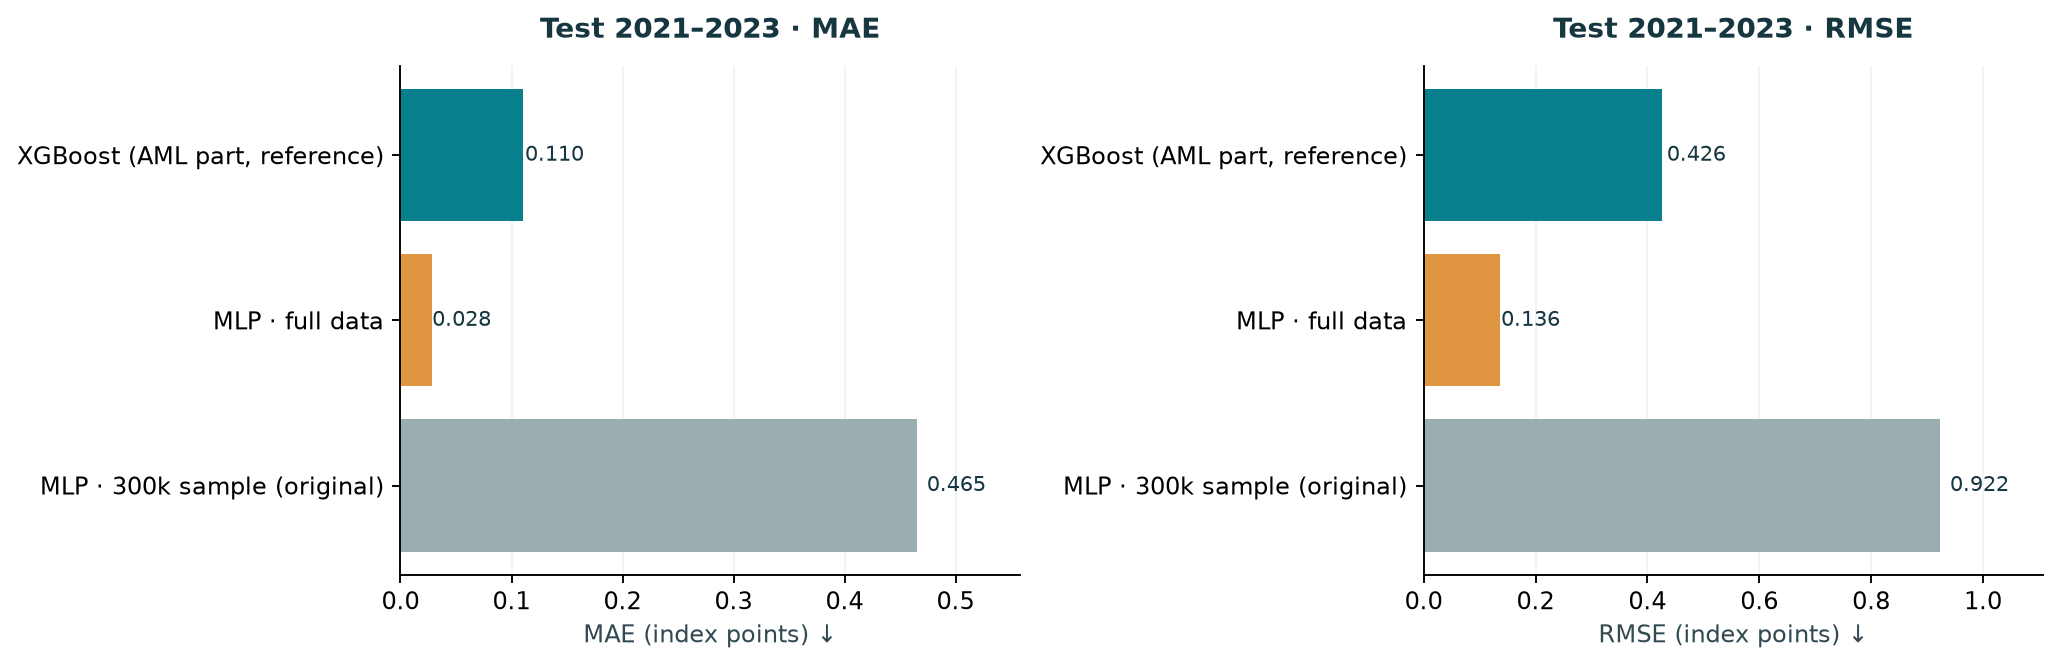

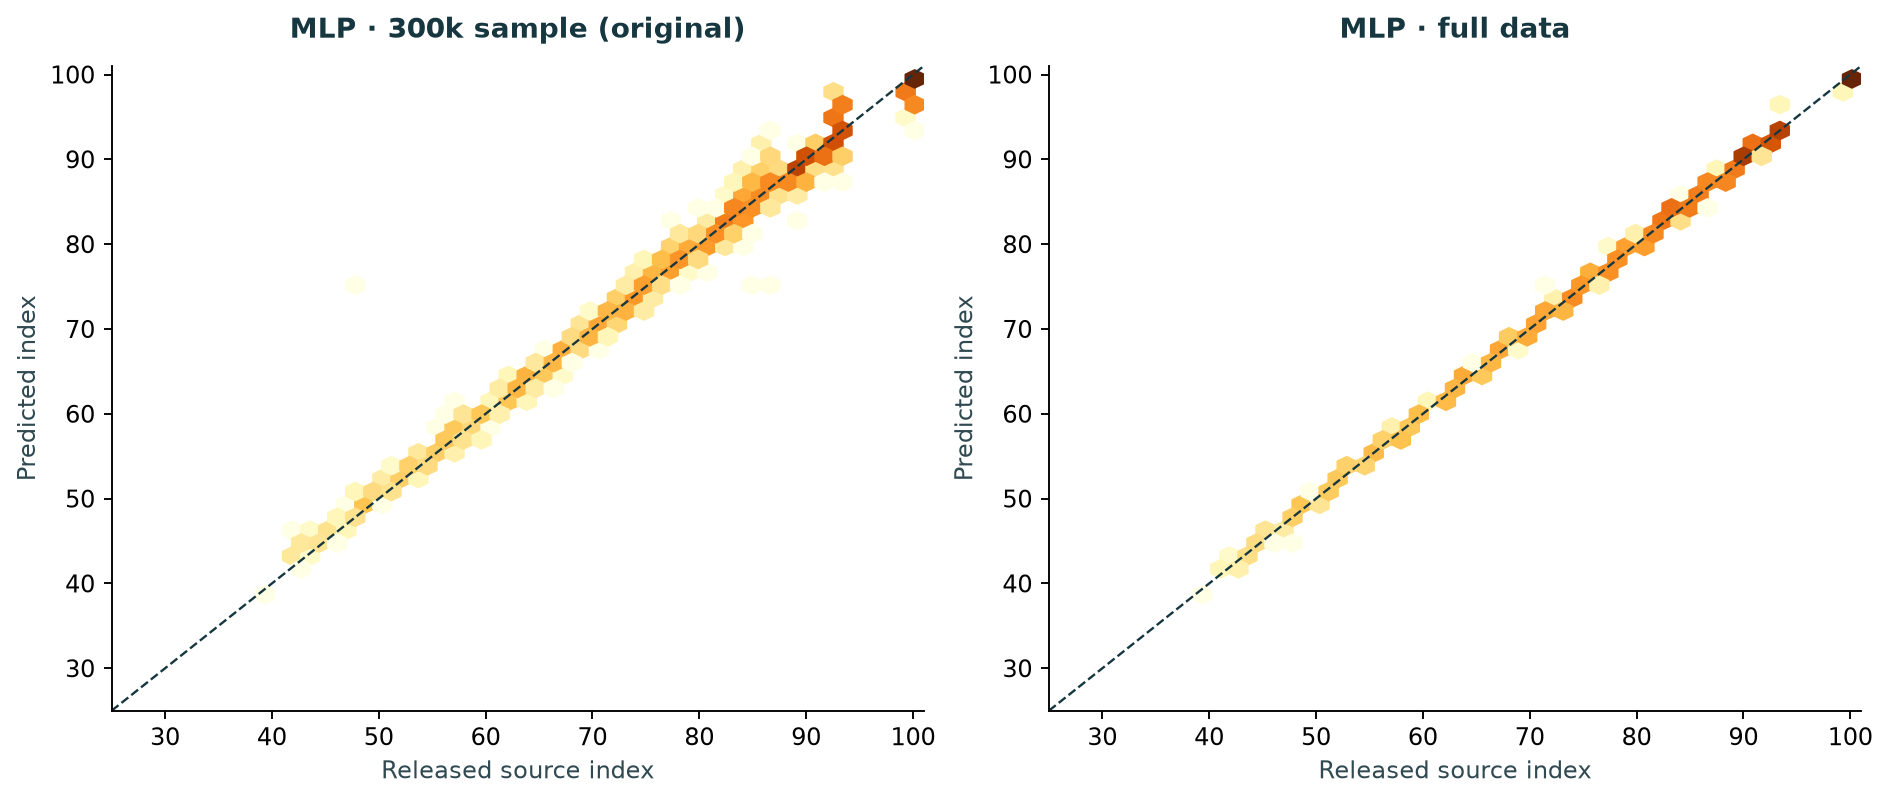

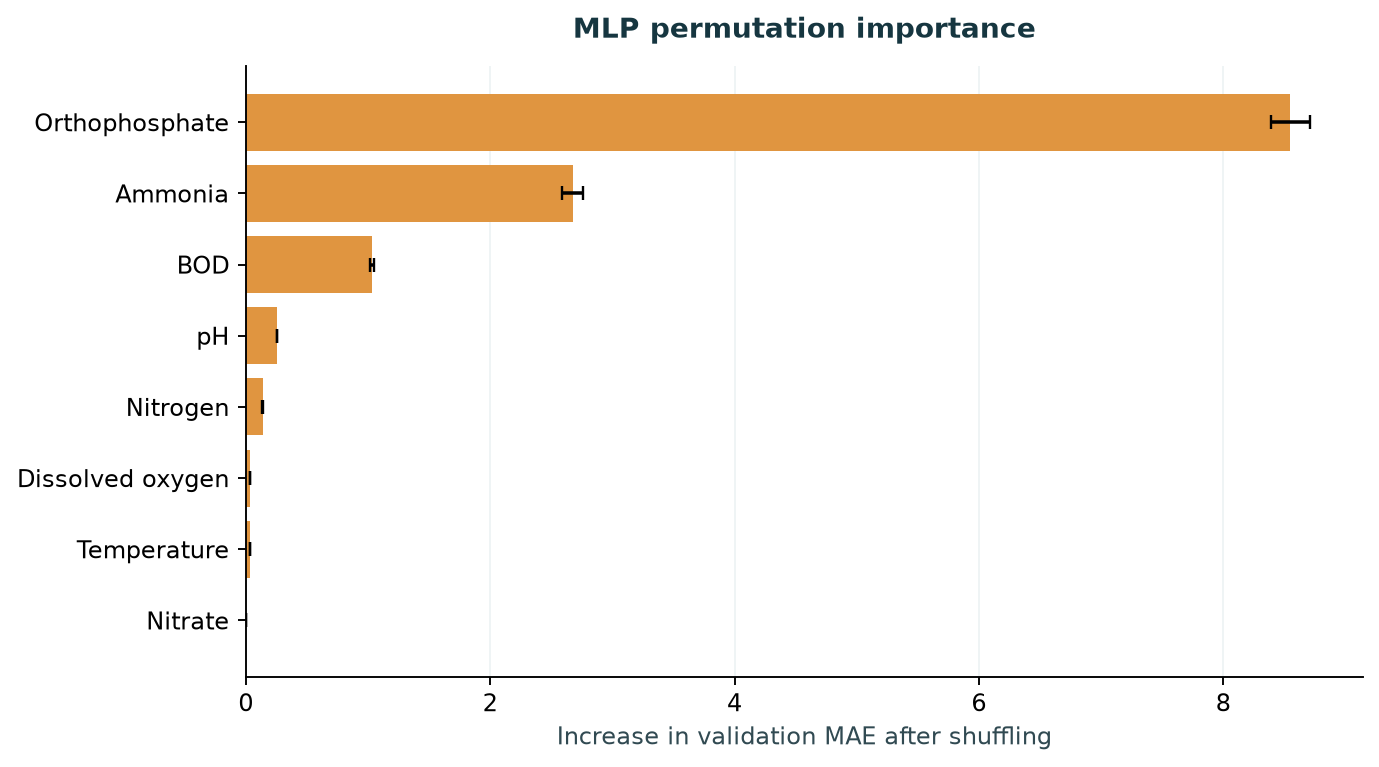

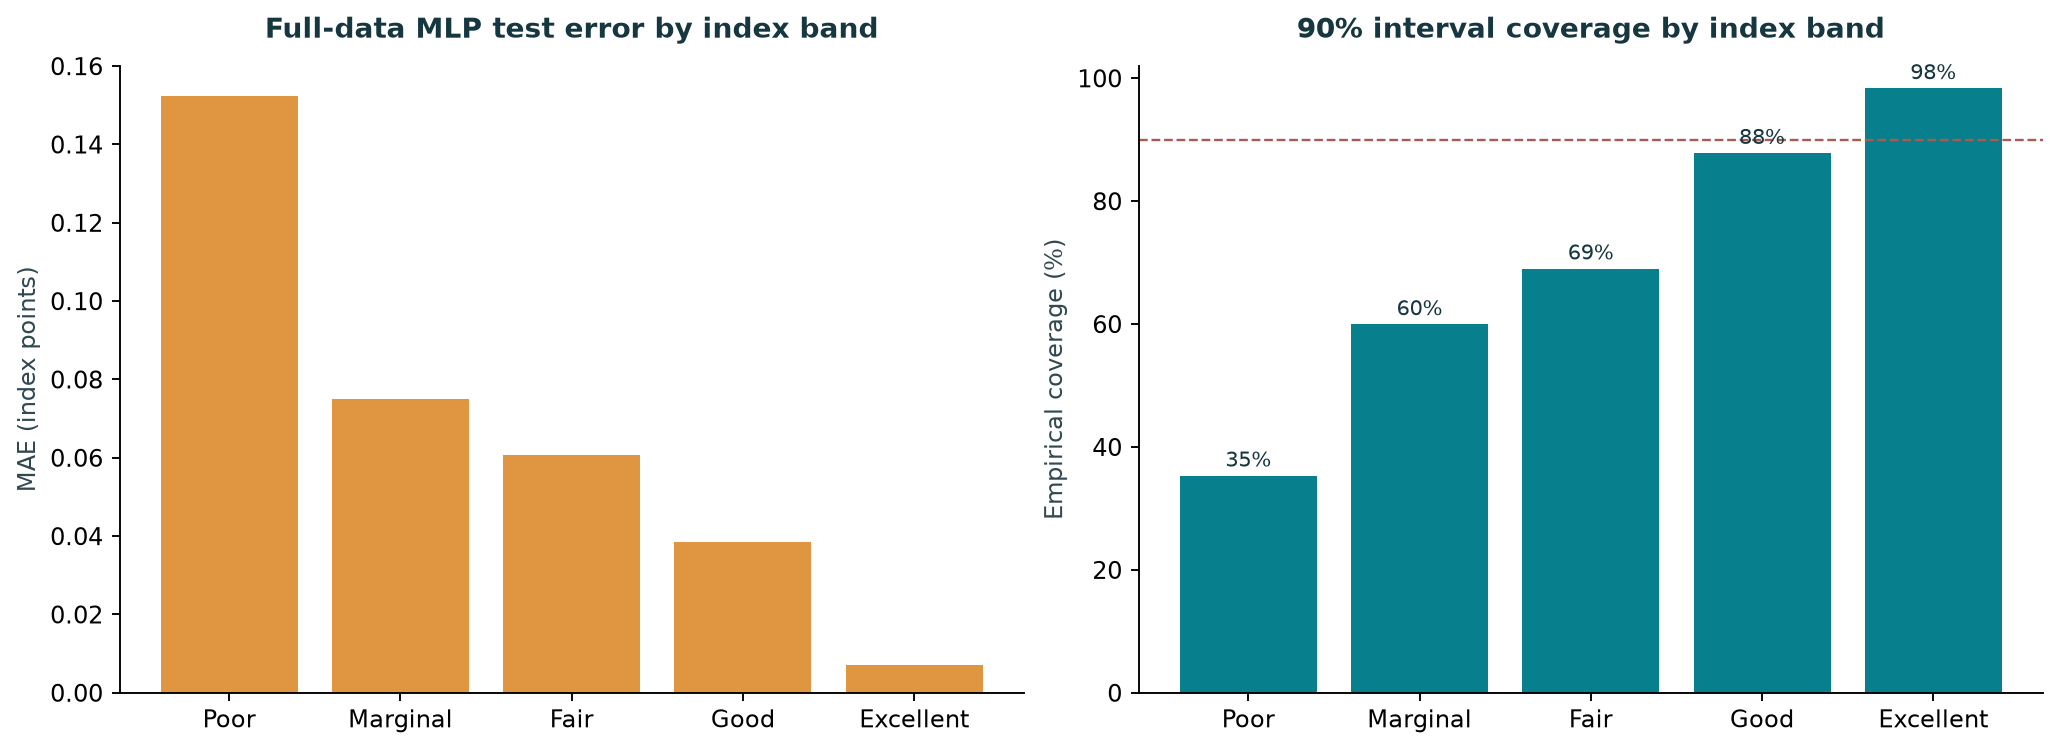

In [7]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelcolor": "#314a52", "text.color": "#163640",
                     "axes.titleweight": "bold", "axes.titlepad": 12,
                     "grid.color": "#dfe9ea", "axes.axisbelow": True})

def show_figure(fig, name):
    path = FIGURES / name
    fig.savefig(path, dpi=170, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path)))

scores = pd.read_csv(RESULTS / "metrics.csv")
groups = pd.read_csv(RESULTS / "subgroup_metrics.csv")
importance = pd.read_csv(RESULTS / "permutation_importance.csv")
predictions = pd.read_csv(RESULTS / "predictions_test.csv.gz")
colors = {"MLP · 300k sample (original)": "#9aaeb2", "MLP · full data": "#e09540", "XGBoost (AML part, reference)": "#087f8c"}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
for ax, metric, label in zip(axes, ["mae", "rmse"], ["MAE (index points) ↓", "RMSE (index points) ↓"]):
    ax.barh(comparison.model, comparison[metric], color=[colors.get(n, "#6893a1") for n in comparison.model])
    for i, v in enumerate(comparison[metric]):
        ax.text(v * 1.02, i, f"{v:.3f}", va="center", fontsize=9)
    ax.set(xlabel=label, title=f"Test 2021–2023 · {metric.upper()}", xlim=(0, comparison[metric].max() * 1.2))
    ax.grid(axis="x", alpha=0.5)
show_figure(fig, "model_comparison.png")

plot_data = predictions.sample(n=8000, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained")
for ax, name in zip(axes, ["MLP · 300k sample (original)", "MLP · full data"]):
    ax.hexbin(plot_data[TARGET], plot_data[name], gridsize=45, bins="log", cmap="YlOrBr",
              mincnt=1, extent=(25, 101, 25, 101))
    ax.plot([25, 101], [25, 101], color="#163640", linestyle="--", linewidth=1)
    ax.set(xlabel="Released source index", ylabel="Predicted index", title=name, xlim=(25, 101), ylim=(25, 101))
show_figure(fig, "actual_vs_predicted.png")

fig, ax = plt.subplots(figsize=(8, 4.4), layout="constrained")
part = importance.sort_values("mae_increase")
ax.barh(part.feature, part.mae_increase, xerr=part.repeat_std, color="#e09540", capsize=3)
ax.set(xlabel="Increase in validation MAE after shuffling", title="MLP permutation importance")
ax.grid(axis="x", alpha=0.5)
show_figure(fig, "feature_importance.png")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), layout="constrained")
part = groups[(groups.group_type == "source_index_band") & (groups.model == "MLP · full data")].set_index("group")
part = part.reindex([b for b in BANDS if b in part.index])
axes[0].bar(part.index, part.mae, color="#e09540")
axes[0].set(ylabel="MAE (index points)", title="Full-data MLP test error by index band")
axes[1].bar(part.index, part.coverage * 100, color="#087f8c")
axes[1].axhline(90, color="#a45d4f", linestyle="--", linewidth=1)
axes[1].set(ylabel="Empirical coverage (%)", ylim=(0, 102), title="90% interval coverage by index band")
for i, v in enumerate(part.coverage * 100):
    axes[1].text(i, v + 1.5, f"{v:.0f}%", ha="center", fontsize=9)
show_figure(fig, "band_performance.png")

## 7. Predict with the reloaded final model
Reload the saved files, verify checksums, then predict five held-out examples. The evaluation network must reproduce its saved test predictions exactly; the final all-years network is shown alongside it. For your own CSV, keep the eight original column headers and units.

In [8]:
metadata = json.loads((MODELS / "metadata.json").read_text())
for filename, expected_hash in json.loads((MODELS / "checksums.json").read_text()).items():
    assert sha256(MODELS / filename) == expected_hash, f"Changed model file: {filename}"
preprocessors = joblib.load(MODELS / "preprocessing.joblib")  # load joblib only from trusted sources
arch = metadata["architecture"]
networks = {}
for key, filename in [("evaluation", "mlp_evaluation.pt"), ("final", "mlp_final_all_years.pt")]:
    net = MLP(arch["input_dim"], arch["widths"], arch["dropout"])
    net.load_state_dict(torch.load(MODELS / filename, map_location="cpu", weights_only=True))
    networks[key] = net.eval()

def predict_measurements(frame, which="final"):
    """Input headers/units must match the dataset; output is the source index (0-100)."""
    features = quality_features(frame)
    prediction = predict_mlp(networks[which], preprocessors[which].transform(features).astype("float32"))
    low, high = intervals(prediction, metadata["interval_radius_90"])
    return pd.DataFrame({"MLP": prediction, "lower_90": low, "upper_90": high,
                         "flagged_inputs": features.iloc[:, 8:].sum(axis=1).to_numpy()}, index=frame.index)

example = pd.read_csv(RESULTS / "Example/measurements.csv")
expected = pd.read_csv(RESULTS / "Example/expected_predictions.csv")
check = predict_measurements(example, "evaluation")
np.testing.assert_allclose(check["MLP"], expected["MLP · full data"], rtol=0, atol=1e-4)
final_result = predict_measurements(example, "final")
display(pd.concat([example, final_result.add_prefix("final_"), expected[[TARGET]]], axis=1).round(3))
print("Reloaded evaluation network reproduces its saved test predictions.")
# new_readings = pd.read_csv("your_measurements.csv")
# predict_measurements(new_readings)

,Ammonia (mg/l),Biochemical Oxygen Demand (mg/l),Dissolved Oxygen (mg/l),Orthophosphate (mg/l),pH (ph units),Temperature (cel),Nitrogen (mg/l),Nitrate (mg/l),final_MLP,final_lower_90,final_upper_90,final_flagged_inputs,CCME_Values
0,0.098,2.7,9.040,0.144,7.95,14.000,5.00,4.500,89.629997,89.579002,89.681000,0.0,89.634
1,0.030,2.7,10.200,0.010,7.78,9.400,0.71,0.706,99.996002,99.945000,100.000000,0.0,100.000
2,0.062,2.7,8.830,0.290,7.81,16.400,1.80,1.770,82.125000,82.073997,82.176003,0.0,82.156
3,0.500,2.7,10.200,0.700,7.78,11.460,18.00,4.500,69.211998,69.161003,69.263000,0.0,69.216
4,0.017,1.4,11.684,0.020,8.00,8.137,0.22,1.300,100.000000,99.948997,100.000000,0.0,100.000


Reloaded evaluation network reproduces its saved test predictions.


## Interpretation and limitations
Training on the whole history, removing dropout and using a one-cycle schedule turns the MLP from the weaker model of the original study into one that matches or beats the XGBoost reference on the untouched 2021–2023 test years. The network has learned to emulate the released formula very closely.

Because the label is a deterministic formula of the inputs, this is index emulation: when all eight readings are available, computing the formula directly is simpler and exact. England dominates the data, most test rows come from previously seen sites, and one constant-radius interval cannot be equally reliable in every index band. The model makes no drinking-water safety decision.

Sources: [Figshare dataset](https://doi.org/10.6084/m9.figshare.27800394.v2), [Deep Learning, chapter 6](https://www.deeplearningbook.org/contents/mlp.html), [One-cycle schedule — Smith & Topin 2019](https://arxiv.org/abs/1708.07120), [Dropout — Srivastava et al. 2014](https://jmlr.org/papers/v15/srivastava14a.html), [Conformal prediction](https://arxiv.org/abs/2107.07511).